In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
print("All Libraries Imported Successfully")

All Libraries Imported Successfully


In [2]:
df = pd.read_csv('karnataka_crop_dataset_V2.csv')
print('Dataset Loaded Successfully')

Dataset Loaded Successfully


In [3]:
df

,N,P,K,temperature,humidity,ph,rainfall,soil_type,season,district,region,label
0,18.75,41.30,40.00,26.92,79.07,6.54,404.90,Loamy,Kharif,Hassan,Malnad,blackgram
1,117.04,29.13,103.92,24.60,51.22,6.17,132.64,Loamy,Rabi,Ramanagara,South Karnataka,mango
2,20.99,21.40,30.00,22.64,59.01,5.58,212.19,Red,Rabi,Tumakuru,South Karnataka,horsegram
3,19.89,46.24,24.29,27.99,53.42,6.51,212.80,Black,Rabi,Koppala,North Karnataka,chickpea
4,53.96,35.99,72.38,33.89,70.89,6.72,148.91,Sandy,Zaid,Chitradurga,South Karnataka,sapota
...,...,...,...,...,...,...,...,...,...,...,...,...
21955,31.41,40.06,74.51,21.26,58.43,7.21,474.30,Sandy,Rabi,Kalaburagi,North Karnataka,pomegranate
21956,37.96,47.12,52.83,29.05,31.77,5.59,416.11,Sandy,Rabi,Kalaburagi,North Karnataka,pomegranate
21957,43.33,27.69,47.62,31.40,30.01,7.11,223.77,Sandy,Rabi,Kalaburagi,North Karnataka,pomegranate
21958,35.74,31.59,59.39,25.10,41.22,7.43,392.47,Sandy,Rabi,Kalaburagi,North Karnataka,pomegranate


In [4]:
df.head() #first 5 row


,N,P,K,temperature,humidity,ph,rainfall,soil_type,season,district,region,label
0,18.75,41.30,40.00,26.92,79.07,6.54,404.90,Loamy,Kharif,Hassan,Malnad,blackgram
1,117.04,29.13,103.92,24.60,51.22,6.17,132.64,Loamy,Rabi,Ramanagara,South Karnataka,mango
2,20.99,21.40,30.00,22.64,59.01,5.58,212.19,Red,Rabi,Tumakuru,South Karnataka,horsegram
3,19.89,46.24,24.29,27.99,53.42,6.51,212.80,Black,Rabi,Koppala,North Karnataka,chickpea
4,53.96,35.99,72.38,33.89,70.89,6.72,148.91,Sandy,Zaid,Chitradurga,South Karnataka,sapota


### Dataset Understanding

In [5]:
df.shape # Check dataset shape (rows, columns)

(21960, 12)

In [6]:
df.info()# check dataset information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21960 entries, 0 to 21959
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            21960 non-null  float64
 1   P            21960 non-null  float64
 2   K            21960 non-null  float64
 3   temperature  21960 non-null  float64
 4   humidity     21960 non-null  float64
 5   ph           21960 non-null  float64
 6   rainfall     21960 non-null  float64
 7   soil_type    21960 non-null  object 
 8   season       21960 non-null  object 
 9   district     21960 non-null  object 
 10  region       21960 non-null  object 
 11  label        21960 non-null  object 
dtypes: float64(7), object(5)
memory usage: 2.0+ MB


### Check Missing Values

In [7]:

df.isnull().sum()


N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
soil_type      0
season         0
district       0
region         0
label          0
dtype: int64

## check Duplicate Values

In [8]:
df.duplicated().sum()

np.int64(0)

### EDA

In [9]:
df.describe() # statistical summary

,N,P,K,temperature,humidity,ph,rainfall
count,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000,21960.000000
mean,87.385183,44.173338,81.801056,26.726448,64.884968,6.440398,475.729599
std,51.958329,13.352457,45.960210,3.810617,13.029716,0.505544,629.358431
min,15.000000,20.000000,15.020000,15.010000,30.010000,4.530000,53.740000
25%,53.387500,37.290000,46.280000,24.170000,55.680000,6.110000,156.357500
50%,76.980000,43.000000,68.520000,26.480000,65.020000,6.450000,283.490000
75%,113.212500,50.030000,108.040000,29.212500,75.130000,6.780000,430.142500
max,279.780000,99.950000,199.990000,37.990000,95.000000,8.000000,3678.950000


In [10]:
df.describe(include='object') # Categorical Data Analysis

,soil_type,season,district,region,label
count,21960,21960,21960,21960,21960
unique,6,3,31,4,39
top,Red,Kharif,Bagalkote,North Karnataka,banana
freq,6582,10060,1580,9200,1200


### Data Visualization


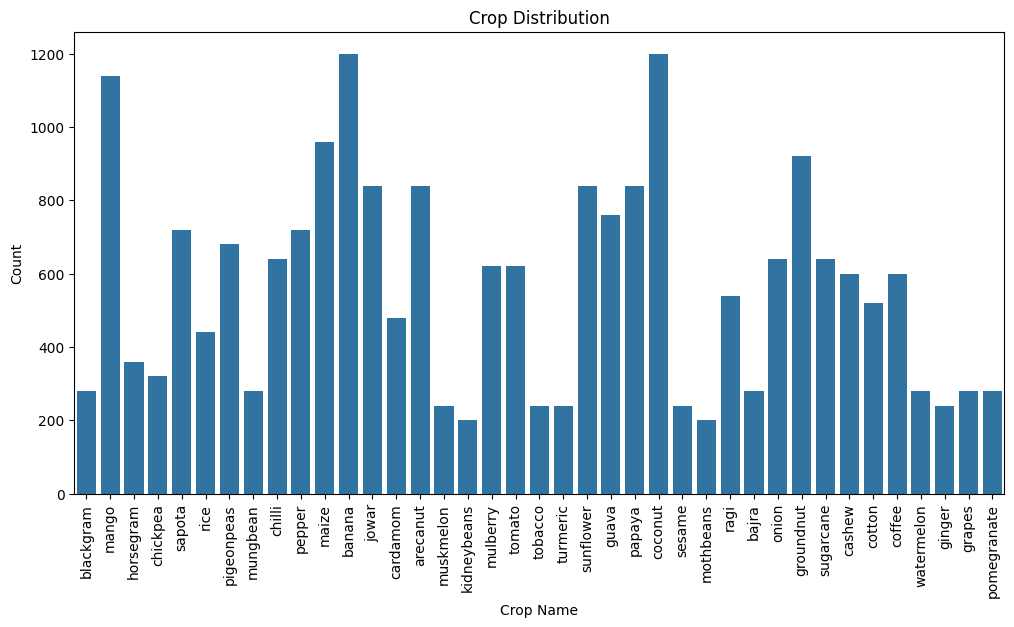

In [11]:
plt.figure(figsize=(12,6)) # graph size
sns.countplot(data=df, x='label')# crop count

plt.title('Crop Distribution') # graph title
plt.xlabel('Crop Name')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()

### Numerical features Distribution

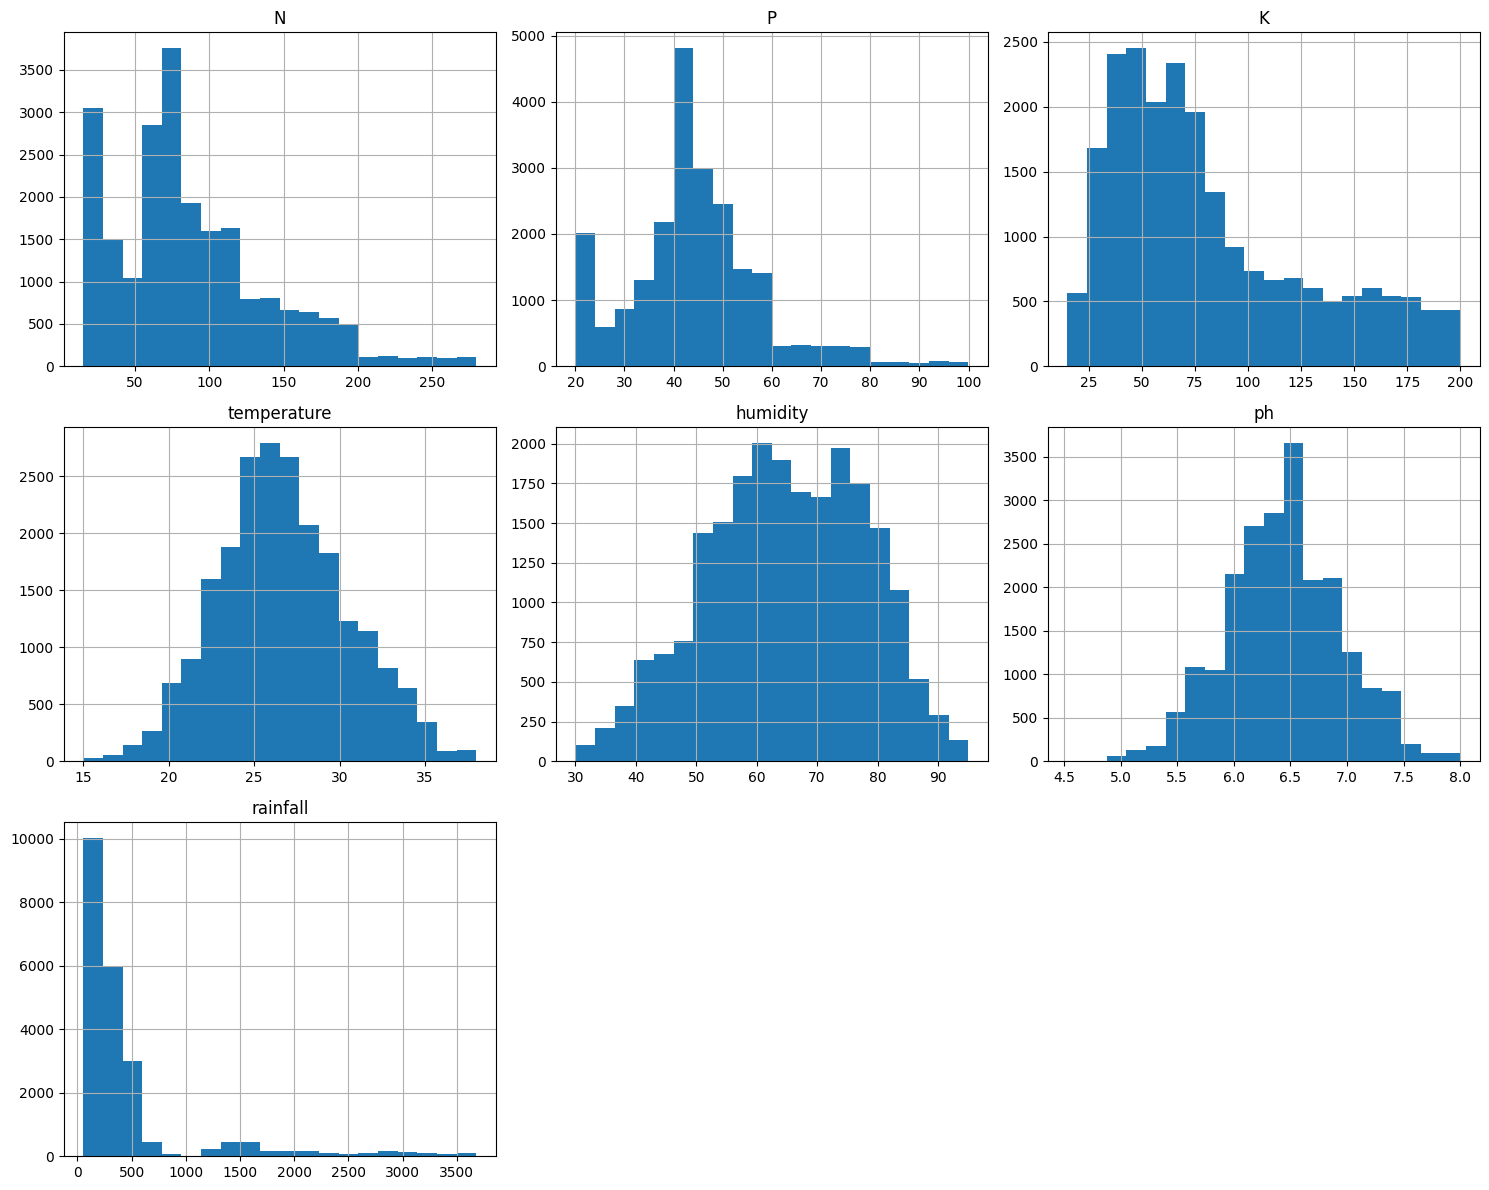

In [12]:
df.hist(figsize=(15,12), bins=20)
plt.tight_layout()
plt.show()

### Outlier Detection(Boxplot)

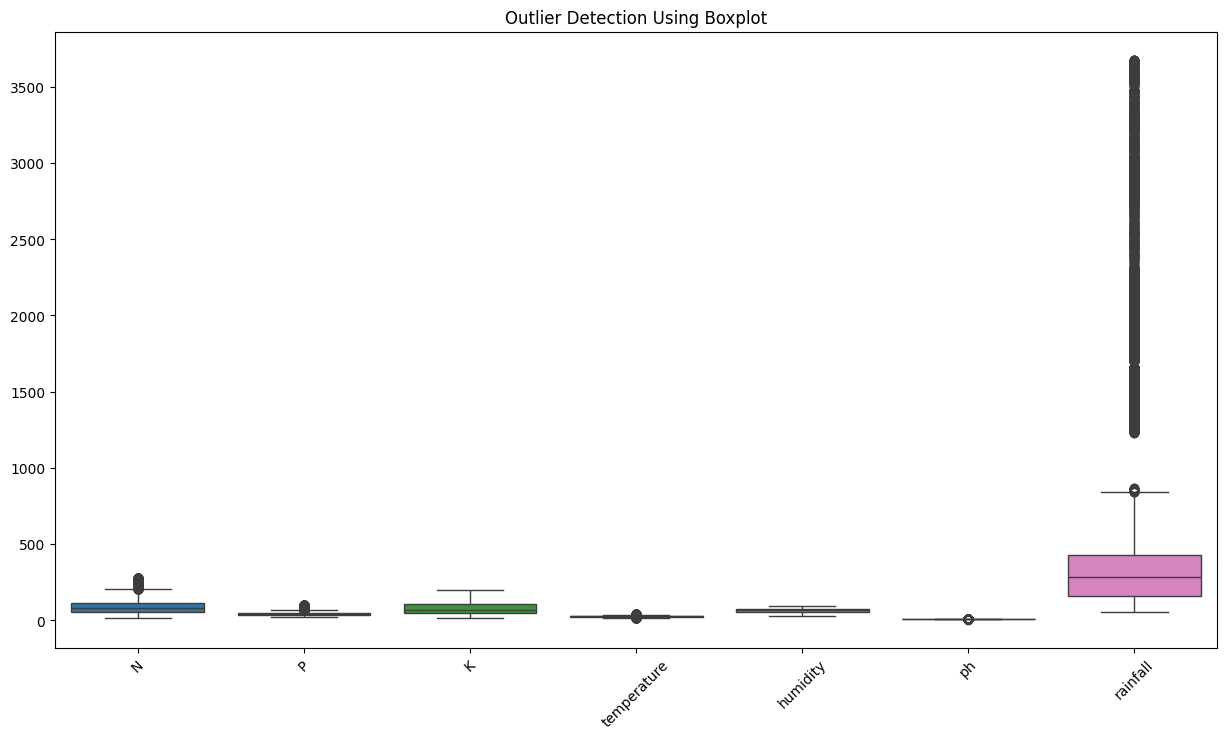

In [13]:
plt.figure(figsize=(15,8))
sns.boxplot(data=df.select_dtypes(include='number'))
plt.title('Outlier Detection Using Boxplot')
plt.xticks(rotation=45)
plt.show()

### Correlation Analysis

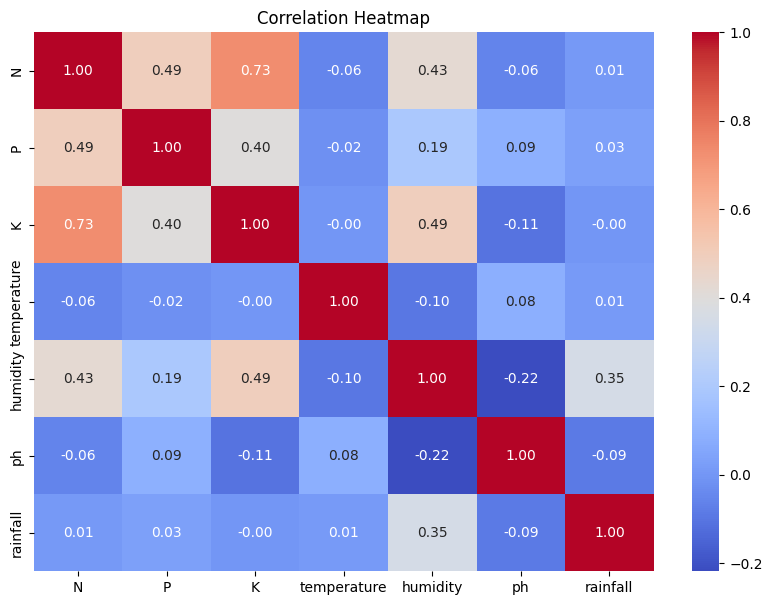

In [14]:
plt.figure(figsize=(10,7))

correlation = df.select_dtypes(include='number').corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

### Categorical Data Visualization

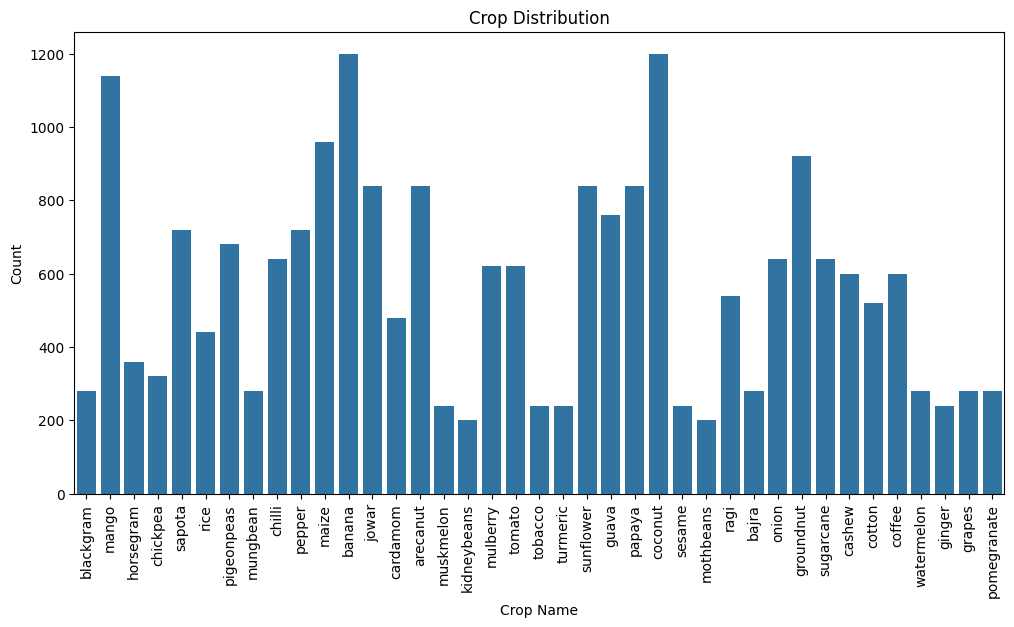

In [15]:
plt.figure(figsize=(12,6))

sns.countplot(data=df, x='label')

plt.title('Crop Distribution')
plt.xlabel('Crop Name')
plt.ylabel('Count')
plt.xticks(rotation=90)

plt.show()

#### Soil type,Season,District,Region Visualization

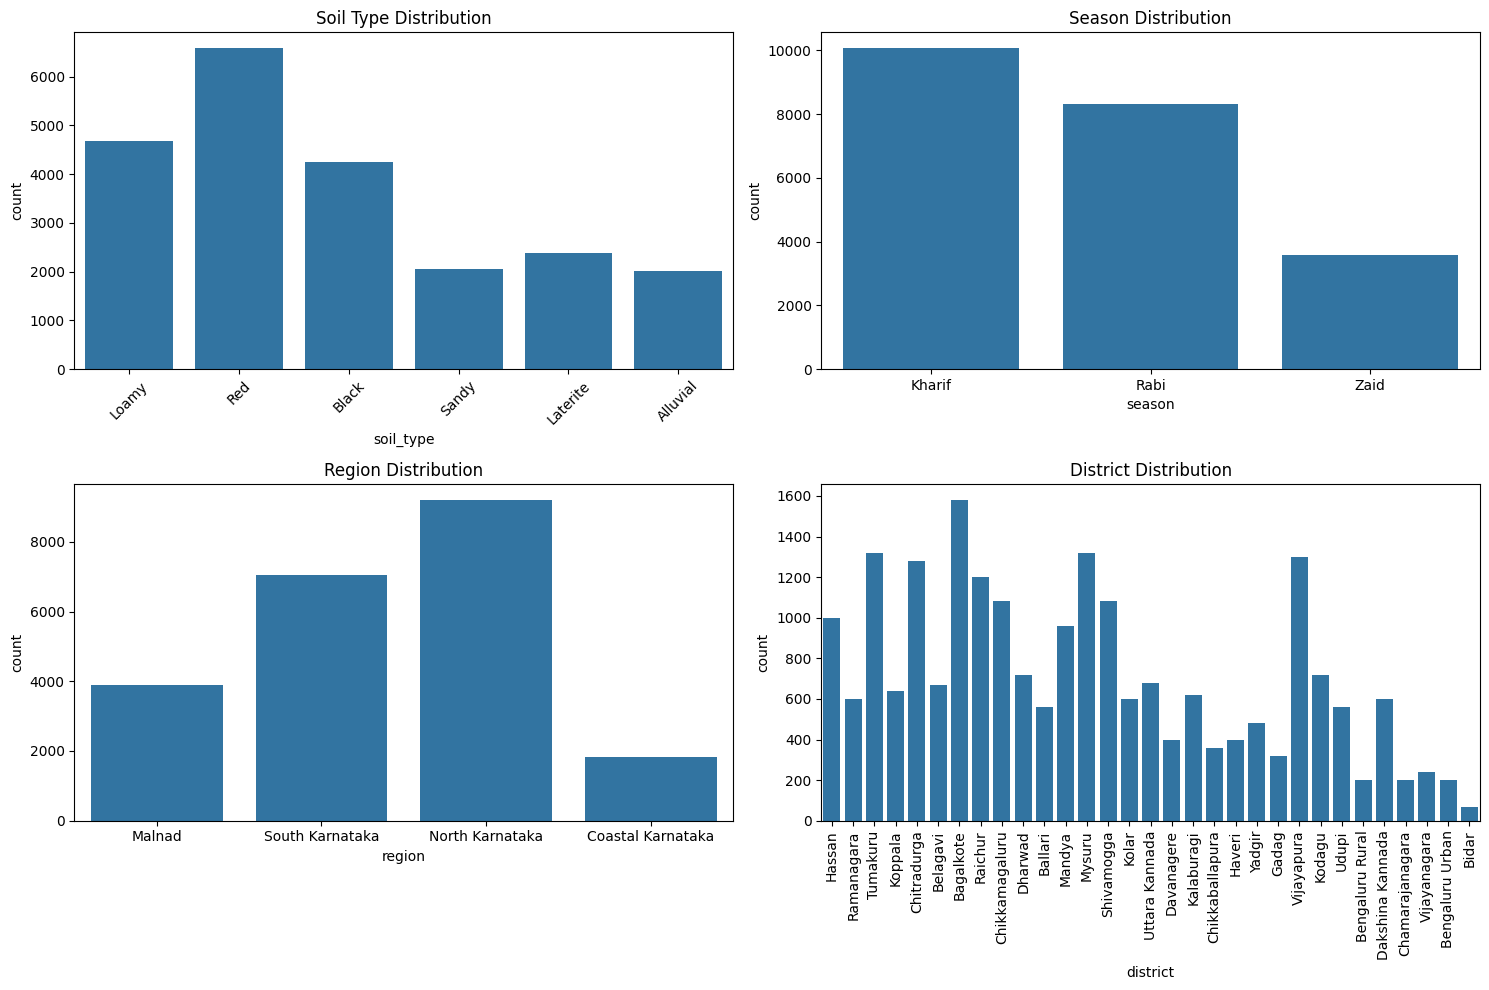

In [16]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
sns.countplot(data=df, x='soil_type')
plt.title('Soil Type Distribution')
plt.xticks(rotation=45)

plt.subplot(2, 2, 2)
sns.countplot(data=df, x='season')
plt.title('Season Distribution')

plt.subplot(2, 2, 3)
sns.countplot(data=df, x='region')
plt.title('Region Distribution')

plt.subplot(2, 2, 4)
sns.countplot(data=df, x='district')
plt.title('District Distribution')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# EDA SUMMARY

1. Dataset contains 21,960 rows and 12 columns.

2. There are 7 numerical columns and 5 categorical columns.

3. No missing values were found.

4. No duplicate records were found.

5. The dataset contains 39 different crop categories.

6. Numerical statistical analysis was performed.

7. Crop distribution was visualized using a count plot.

8. Numerical features were analyzed using histograms.

9. Outliers were detected using boxplots.

10. Correlation analysis was performed using a heatmap.

11. Categorical features were visualized using count plots.

12. Red soil and Kharif season have the highest frequency.

13. North Karnataka has the highest regional frequency.

### DATA PREPROCESSING

In [17]:
# Create a copy of the original dataset

df1 = df.copy()

print("Dataset copied successfully")

print("Original Dataset Shape:", df.shape)

print("New Dataset Shape:", df1.shape)

Dataset copied successfully
Original Dataset Shape: (21960, 12)
New Dataset Shape: (21960, 12)


### Handling Missing Values

In [18]:
# check missing values
df1.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
soil_type      0
season         0
district       0
region         0
label          0
dtype: int64

### Handling Duplicate Values

In [19]:
# check duplicate values
print("Duplicate Rows:",df1.duplicated().sum())

Duplicate Rows: 0


### Handling Outliers

In [20]:
# Detect Outliers using IQR

numerical_cols = df1.select_dtypes(include='number').columns

for col in numerical_cols:
    Q1 = df1[col].quantile(0.25)
    Q3 = df1[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df1[(df1[col] < lower) | (df1[col] > upper)]

    print(col, ":", len(outliers))

N : 617
P : 1132
K : 0
temperature : 155
humidity : 0
ph : 236
rainfall : 2465


In [21]:
# Check Outlier Range

for col in numerical_cols:
    Q1 = df1[col].quantile(0.25)
    Q3 = df1[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df1[(df1[col] < lower) | (df1[col] > upper)]

    if len(outliers) > 0:
        print("\n", col)
        print("Minimum Outlier:", outliers[col].min())
        print("Maximum Outlier:", outliers[col].max())
        #“Outliers were detected using the IQR method. Since these values may represent valid agricultural conditions, they were retained without removal.”


 N
Minimum Outlier: 202.96
Maximum Outlier: 279.78

 P
Minimum Outlier: 69.15
Maximum Outlier: 99.95

 temperature
Minimum Outlier: 15.01
Maximum Outlier: 37.99

 ph
Minimum Outlier: 4.53
Maximum Outlier: 8.0

 rainfall
Minimum Outlier: 840.98
Maximum Outlier: 3678.95


### Encoding Categorical Variables

In [22]:
#Label encoding
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df1['label'] = le.fit_transform(df1['label'])

In [23]:
df1.head()

,N,P,K,temperature,humidity,ph,rainfall,soil_type,season,district,region,label
0,18.75,41.30,40.00,26.92,79.07,6.54,404.90,Loamy,Kharif,Hassan,Malnad,3
1,117.04,29.13,103.92,24.60,51.22,6.17,132.64,Loamy,Rabi,Ramanagara,South Karnataka,19
2,20.99,21.40,30.00,22.64,59.01,5.58,212.19,Red,Rabi,Tumakuru,South Karnataka,15
3,19.89,46.24,24.29,27.99,53.42,6.51,212.80,Black,Rabi,Koppala,North Karnataka,6
4,53.96,35.99,72.38,33.89,70.89,6.72,148.91,Sandy,Zaid,Chitradurga,South Karnataka,31


In [24]:
df1.shape

(21960, 12)

### Feature and Target Separation

In [25]:
# Separate input and output variables

X = df1.drop('label', axis=1)
y = df1['label']

print("X Shape:", X.shape)
print("y Shape:", y.shape)


X Shape: (21960, 11)
y Shape: (21960,)


In [26]:
X

,N,P,K,temperature,humidity,ph,rainfall,soil_type,season,district,region
0,18.75,41.30,40.00,26.92,79.07,6.54,404.90,Loamy,Kharif,Hassan,Malnad
1,117.04,29.13,103.92,24.60,51.22,6.17,132.64,Loamy,Rabi,Ramanagara,South Karnataka
2,20.99,21.40,30.00,22.64,59.01,5.58,212.19,Red,Rabi,Tumakuru,South Karnataka
3,19.89,46.24,24.29,27.99,53.42,6.51,212.80,Black,Rabi,Koppala,North Karnataka
4,53.96,35.99,72.38,33.89,70.89,6.72,148.91,Sandy,Zaid,Chitradurga,South Karnataka
...,...,...,...,...,...,...,...,...,...,...,...
21955,31.41,40.06,74.51,21.26,58.43,7.21,474.30,Sandy,Rabi,Kalaburagi,North Karnataka
21956,37.96,47.12,52.83,29.05,31.77,5.59,416.11,Sandy,Rabi,Kalaburagi,North Karnataka
21957,43.33,27.69,47.62,31.40,30.01,7.11,223.77,Sandy,Rabi,Kalaburagi,North Karnataka
21958,35.74,31.59,59.39,25.10,41.22,7.43,392.47,Sandy,Rabi,Kalaburagi,North Karnataka


In [27]:
y

0         3
1        19
2        15
3         6
4        31
         ..
21955    28
21956    28
21957    28
21958    28
21959    28
Name: label, Length: 21960, dtype: int64

In [28]:


# check shape
print("x Shape:", X.shape)
print("y Shape:", y.shape)

x Shape: (21960, 11)
y Shape: (21960,)


### Train-Test Split

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (17568, 11)
X_test: (4392, 11)
y_train: (17568,)
y_test: (4392,)


In [30]:
# One-Hot Encoding

categorical_cols = ['soil_type', 'season', 'district', 'region']

X_train = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    dtype=int
)

# Match test columns with training columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)

X_train Shape: (17568, 51)
X_test Shape: (4392, 51)


### Feature Scaling(standardization)

In [31]:
# import StandardScaler
from sklearn.preprocessing import StandardScaler

In [32]:
# Apply standard scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [33]:
print("X_train_scaled:", X_train_scaled.shape)

print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (17568, 51)
X_test_scaled: (4392, 51)


### Model Building-Random Forest Classifier

In [34]:
#import random forest
from sklearn.ensemble import RandomForestClassifier

In [35]:
# create the model
model = RandomForestClassifier(n_estimators=100, random_state=42)

In [36]:
# Train the model
model.fit(X_train_scaled, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [37]:
#check
print("Model Training Completed Successfully!")

Model Training Completed Successfully!


# Model Prediction

In [38]:
# prediction test data
y_pred = model.predict(X_test_scaled)


In [39]:
# check predicition
print("Predicted Values:", y_pred[:10])

print("Actual Values:", y_test[:10].values)



Predicted Values: [23  0 19 14 16 24 13  9  5  5]
Actual Values: [38  0 19 14 16 24 13 26  5  5]


In [40]:
## check predicition lengath
print("Total Predictions:", len(y_pred))

Total Predictions: 4392


In [41]:
# Accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100)

Model Accuracy: 90.80145719489981


In [42]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report")

print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_,
    zero_division=0
))

Random Forest Classification Report
              precision    recall  f1-score   support

    arecanut       0.80      0.86      0.83       168
       bajra       0.96      0.86      0.91        56
      banana       0.87      1.00      0.93       240
   blackgram       0.77      0.77      0.77        56
    cardamom       0.84      0.78      0.81        96
      cashew       1.00      1.00      1.00       120
    chickpea       0.85      0.88      0.86        64
      chilli       0.86      0.88      0.87       128
     coconut       0.87      0.79      0.83       240
      coffee       0.91      0.94      0.93       120
      cotton       0.98      0.92      0.95       104
      ginger       0.61      0.81      0.70        48
      grapes       1.00      1.00      1.00        56
   groundnut       1.00      1.00      1.00       184
       guava       0.93      0.76      0.83       152
   horsegram       1.00      1.00      1.00        72
       jowar       0.94      0.97      0.96  

In [43]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluation Metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print("MODEL EVALUATION METRICS")
print("------------------------")
print("Accuracy  :", round(accuracy * 100, 2), "%")
print("Precision :", round(precision * 100, 2), "%")
print("Recall    :", round(recall * 100, 2), "%")
print("F1 Score  :", round(f1 * 100, 2), "%")


MODEL EVALUATION METRICS
------------------------
Accuracy  : 90.8 %
Precision : 91.02 %
Recall    : 90.8 %
F1 Score  : 90.76 %


In [44]:
# Save Model Evaluation Results

import pickle

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),

    "precision": precision_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    ),

    "recall": recall_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    ),

    "f1": f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    ),

    "y_test": y_test,
    "y_pred": y_pred
}

with open("model_metrics.pkl", "wb") as file:
    pickle.dump(metrics, file)

print("Model Evaluation Results Saved Successfully!")

Model Evaluation Results Saved Successfully!


### Confusion Matrix

In [45]:
# import libraries
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [46]:
# create confusion matrix
cm = confusion_matrix(y_test, y_pred)

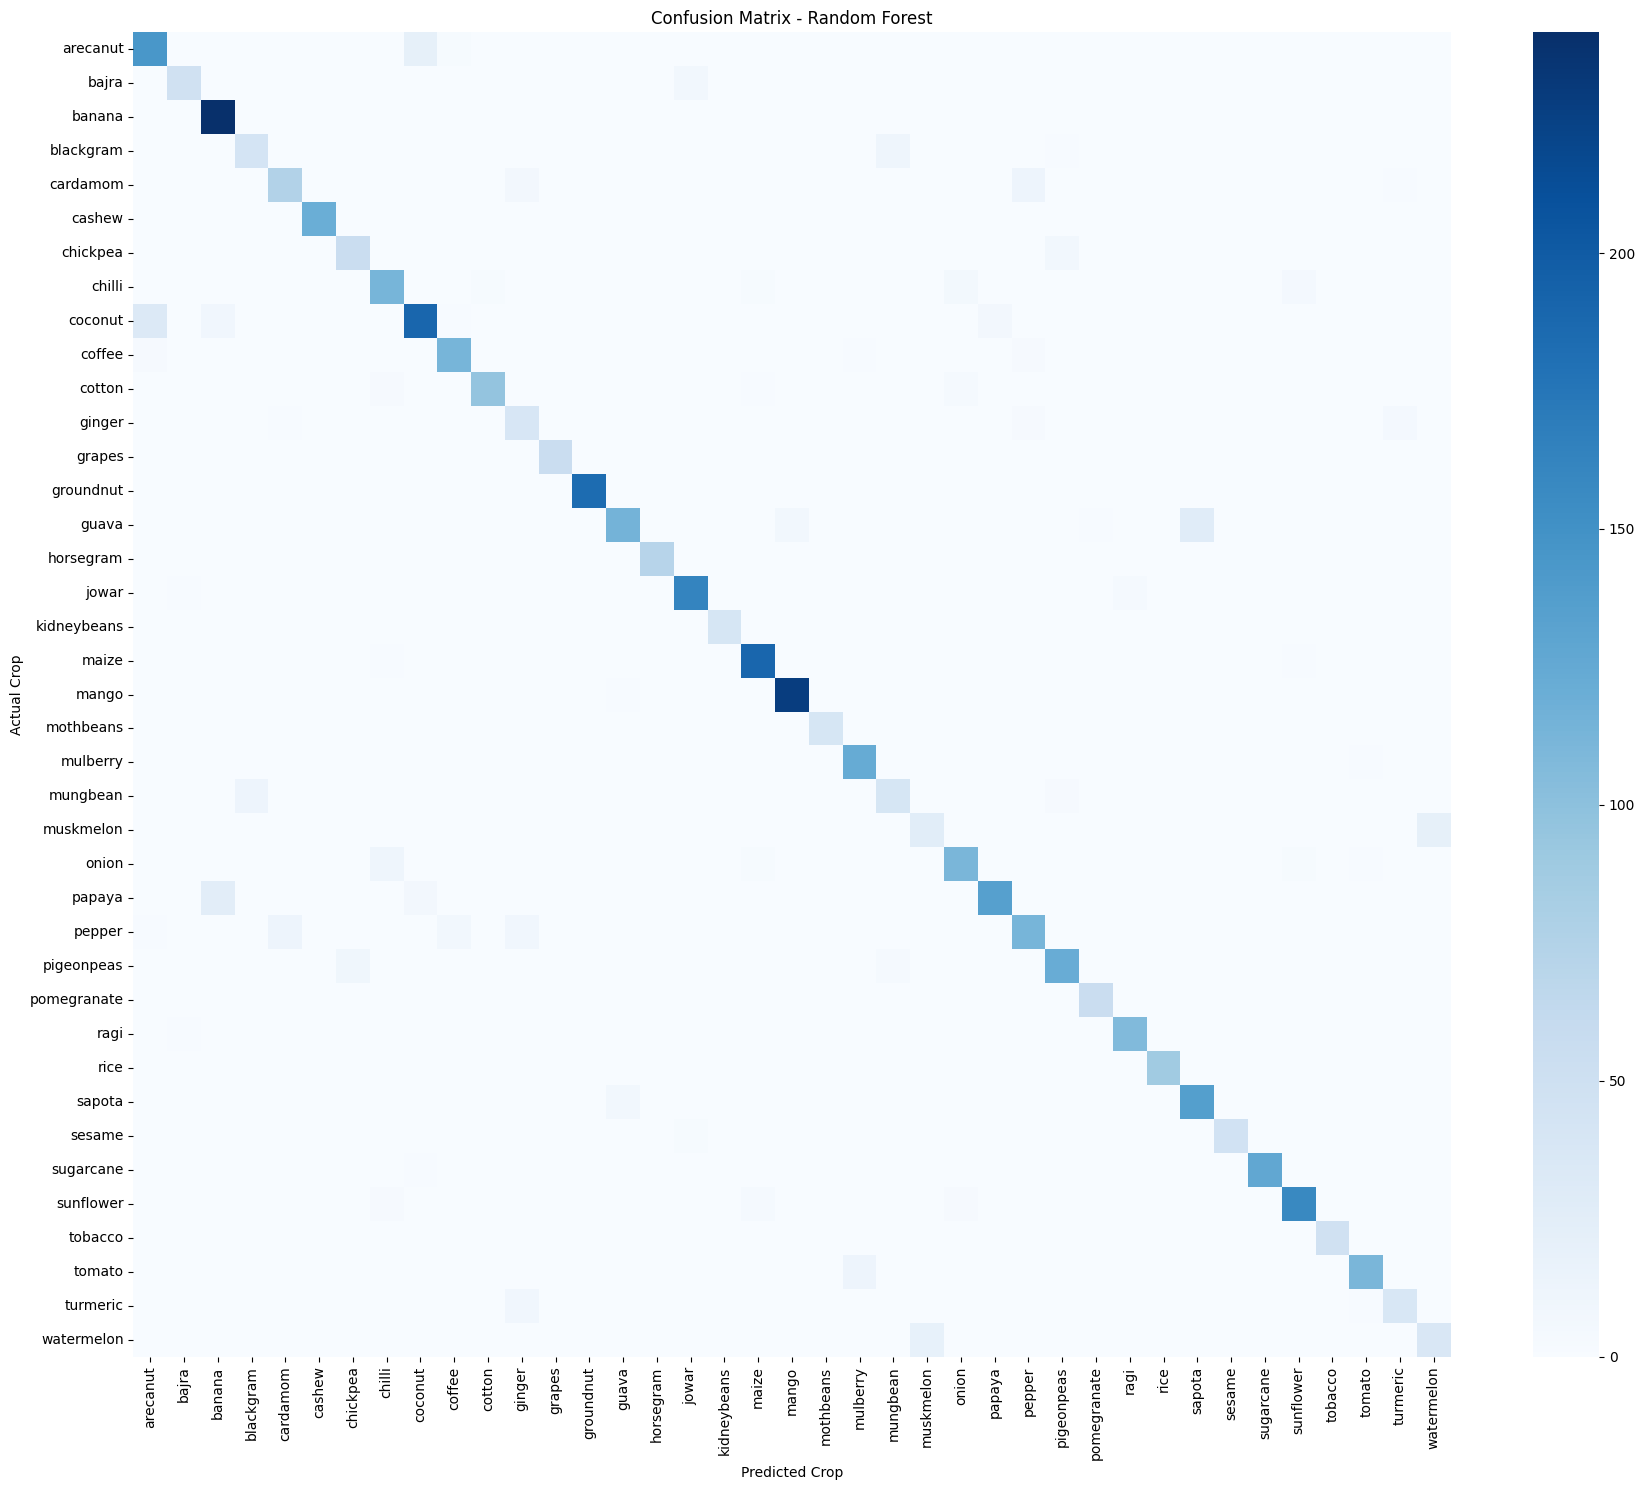

In [47]:
# visualize confusion matrix
plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    annot=False,
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Crop Recommendation(model testing)

In [48]:

# Select one sample from test data

input_data = X_test.iloc[[0]]

input_data

,N,P,K,temperature,humidity,ph,rainfall,soil_type_Alluvial,soil_type_Black,soil_type_Laterite,...,district_Tumakuru,district_Udupi,district_Uttara Kannada,district_Vijayanagara,district_Vijayapura,district_Yadgir,region_Coastal Karnataka,region_Malnad,region_North Karnataka,region_South Karnataka
10111,71.0,54.34,83.8,35.17,41.04,6.05,69.58,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [49]:
# feature scaling
input_scaled = scaler.transform(input_data)

In [50]:
# predict the crop
prediction = model.predict(input_scaled)

predicted_crop = le.inverse_transform(prediction)

print("Recommended Crop:", predicted_crop[0])

Recommended Crop: muskmelon


In [51]:
# check Actual crop
actual_crop = le.inverse_transform([y_test.iloc[0]])

print("Actual Crop:", actual_crop[0])

Actual Crop: watermelon


## Manual Crop Recommendation¶

In [52]:

# Sample Prediction Using First Dataset Row

manual_input = X.iloc[[0]].copy()

# Apply One-Hot Encoding
manual_input = pd.get_dummies(
    manual_input,
    columns=categorical_cols,
    dtype=int
)

# Match training columns
manual_input = manual_input.reindex(
    columns=X_train.columns,
    fill_value=0
)

manual_input

,N,P,K,temperature,humidity,ph,rainfall,soil_type_Alluvial,soil_type_Black,soil_type_Laterite,...,district_Tumakuru,district_Udupi,district_Uttara Kannada,district_Vijayanagara,district_Vijayapura,district_Yadgir,region_Coastal Karnataka,region_Malnad,region_North Karnataka,region_South Karnataka
0,18.75,41.3,40.0,26.92,79.07,6.54,404.9,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [53]:
# Feature Scaling
manual_scaled = scaler.transform(manual_input)

In [54]:
# prediction crop
manual_prediction = model.predict(manual_scaled)

recommended_crop = le.inverse_transform(manual_prediction)

print("Recommended Crop:", recommended_crop[0])

Recommended Crop: blackgram


### Model Comparison¶

### Decision Tree Classifier

In [55]:
# import decision tree
from sklearn.tree import DecisionTreeClassifier

In [56]:
# create the model
dt_model = DecisionTreeClassifier(random_state=42)

In [57]:
# train the model\
dt_model.fit(X_train_scaled, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [58]:
# check traing
print("Decision Tree Training Completed Successfully!")

Decision Tree Training Completed Successfully!


In [59]:
# decision tree predicition
# predict the test data
dt_pred = dt_model.predict(X_test_scaled)

In [60]:
# check prediction
print("Predicted Values:", dt_pred[:10])

print("Actual Values:", y_test[:10].values)

Predicted Values: [38  0 19 14 16 24 13  9  5  5]
Actual Values: [38  0 19 14 16 24 13 26  5  5]


In [61]:
# Decision tree accuracy
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy * 100)

Decision Tree Accuracy: 88.9344262295082


In [62]:
# Decision Tree Evaluation Metrics

from sklearn.metrics import precision_score, recall_score, f1_score

dt_precision = precision_score(y_test, dt_pred, average="weighted", zero_division=0)

dt_recall = recall_score(y_test, dt_pred, average="weighted", zero_division=0)

dt_f1 = f1_score(y_test, dt_pred, average="weighted", zero_division=0)

print("Decision Tree Precision:", round(dt_precision * 100, 2), "%")
print("Decision Tree Recall:", round(dt_recall * 100, 2), "%")
print("Decision Tree F1 Score:", round(dt_f1 * 100, 2), "%")



Decision Tree Precision: 88.95 %
Decision Tree Recall: 88.93 %
Decision Tree F1 Score: 88.91 %


### Model Comparison Table

In [63]:
import pandas as pd

comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Decision Tree'],
    'Accuracy': [accuracy * 100, dt_accuracy * 100]
})

comparison

,Model,Accuracy
0,Random Forest,90.801457
1,Decision Tree,88.934426


### Model Comparison Graph

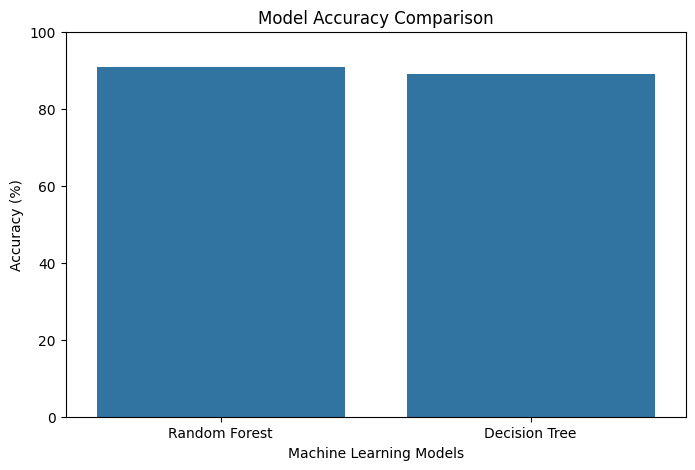

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=comparison
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xlabel("Machine Learning Models")

plt.ylim(0, 100)

plt.show()

## Project Conclusion
The Smart Crop Recommendation System was developed using Machine Learning classification algorithms.

Two algorithms were implemented:

Random Forest Classifier
Decision Tree Classifier
The model performance was evaluated using accuracy, classification report, and confusion matrix.

Random Forest achieved 90.80% accuracy, while Decision Tree achieved 88.93% accuracy.

Therefore, Random Forest was selected as the best-performing model.

The system recommends suitable crops based on soil nutrients and environmental conditions.

This project helps farmers make better crop selection decisions.

In [65]:
# final model saving

In [66]:
import pickle

In [67]:
# save the model
with open("smart_crop_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model Saved Successfully!")

Model Saved Successfully!


In [68]:
#save the scaler
with open("scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

print("Scaler Saved Successfully!")

Scaler Saved Successfully!


In [69]:
# Save Label Encoder

with open("label_encoder.pkl", "wb") as file:
    pickle.dump(le, file)

print("Label Encoder Saved Successfully!")

Label Encoder Saved Successfully!


In [70]:
# Save Feature Columns

with open("feature_columns.pkl", "wb") as file:
    pickle.dump(X.columns.tolist(), file)

print("Feature Columns Saved Successfully!")

Feature Columns Saved Successfully!


In [71]:
import pickle

with open("feature_columns.pkl", "rb") as file:
    feature_columns = pickle.load(file)

print("Number of Features:", len(feature_columns))
print("Feature Columns:")
print(feature_columns)

Number of Features: 11
Feature Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'soil_type', 'season', 'district', 'region']


In [72]:
df.head(5)

,N,P,K,temperature,humidity,ph,rainfall,soil_type,season,district,region,label
0,18.75,41.30,40.00,26.92,79.07,6.54,404.90,Loamy,Kharif,Hassan,Malnad,blackgram
1,117.04,29.13,103.92,24.60,51.22,6.17,132.64,Loamy,Rabi,Ramanagara,South Karnataka,mango
2,20.99,21.40,30.00,22.64,59.01,5.58,212.19,Red,Rabi,Tumakuru,South Karnataka,horsegram
3,19.89,46.24,24.29,27.99,53.42,6.51,212.80,Black,Rabi,Koppala,North Karnataka,chickpea
4,53.96,35.99,72.38,33.89,70.89,6.72,148.91,Sandy,Zaid,Chitradurga,South Karnataka,sapota


In [73]:
# Test Multiple Samples

test_samples = X_test.head(10)

# Apply Scaling
test_samples_scaled = scaler.transform(test_samples)

# Make Predictions
predictions = model.predict(test_samples_scaled)

# Display Actual Crops
print("Actual Crops:")
print(le.inverse_transform(y_test.head(10)))

# Display Predicted Crops
print("\nPredicted Crops:")
print(le.inverse_transform(predictions))

Actual Crops:
['watermelon' 'arecanut' 'mango' 'guava' 'jowar' 'onion' 'groundnut'
 'pepper' 'cashew' 'cashew']

Predicted Crops:
['muskmelon' 'arecanut' 'mango' 'guava' 'jowar' 'onion' 'groundnut'
 'coffee' 'cashew' 'cashew']


In [74]:
# Overall Test Accuracy

from sklearn.metrics import accuracy_score

# Scale Test Data
X_test_scaled = scaler.transform(X_test)

# Predict Test Data
y_pred = model.predict(X_test_scaled)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 90.80145719489981 %


In [75]:
print(model)

RandomForestClassifier(random_state=42)


In [76]:
print("Model:", type(model))

print("Model Features:", model.n_features_in_)

print("Scaler Features:", scaler.n_features_in_)

print("Saved Feature Columns:", len(feature_columns))

Model: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Model Features: 51
Scaler Features: 51
Saved Feature Columns: 11


In [77]:
# Correct Feature Columns

feature_columns = scaler.feature_names_in_.tolist()

# Save Feature Columns

with open("feature_columns.pkl", "wb") as file:
    pickle.dump(feature_columns, file)

print("Feature Columns Saved Successfully!")
print("Total Features:", len(feature_columns))

Feature Columns Saved Successfully!
Total Features: 51


In [78]:
with open("feature_columns.pkl", "rb") as file:
    feature_columns = pickle.load(file)

print("Model Features:", model.n_features_in_)
print("Scaler Features:", scaler.n_features_in_)
print("Saved Features:", len(feature_columns))

Model Features: 51
Scaler Features: 51
Saved Features: 51
